# Informe técnico · Gemelo digital de una electrolinera de autopista

**Proyecto:** `electrolinera-ap7` · **Autor:** Adrián Colomo Moragues · **Última actualización:** 16/10/2026

Proyecto propio basado en un caso práctico de una asignatura del Grado en Ciencia de Datos e Inteligencia Artificial (UMH). Este informe documenta los datos, los modelos, su validación, el simulador y las conclusiones. Todas las cifras se calculan al ejecutarlo.

| Fase | Contenido | Estado |
|---|---|---|
| 1 | Exploración de los datos y ajuste de modelos propios | ✅ |
| 2 | Simulador Monte Carlo vectorizado y validación | ✅ |
| 3 | Optimización de la batería y escenarios | ✅ |
| 4 | App Streamlit, tests y CI | ✅ |
| 5 | Publicación | ⏳ |

> Ejecútalo desde la raíz del proyecto con `pip install -r requirements-dev.txt`. La primera celda descarga los datos de la fuente si no están en `data/`.

## 1. El caso

Una electrolinera de gran tamaño en la **AP-7** atiende a todos los vehículos que llegan, con cargadores de cuatro tipos:

| Tipo | Vehículos típicos | Potencia | Precio de venta |
|---|---|---|---|
| AC/PHEV | híbridos enchufables, urbanos | 11 kW | 0,30 €/kWh |
| DC Estándar | eléctricos de 400 V (Kona, e-208, Leaf…) | 50 kW | 0,40 €/kWh |
| HPC 150 | Tesla Model 3/Y, ID.4, Enyaq… | 80–130 kW | 0,60 €/kWh |
| HPC 350 | 800 V (Ioniq 5, EV6, Taycan…) | ~200 kW | 0,75 €/kWh |

La energía se compra a 0,20 €/kWh. El **transformador** admite 11 500 kW: si en una hora la potencia instantánea total (PIT) lo supera, se corta el servicio, se pierde la facturación de esa hora y la reparación cuesta Triangular(1 500, 2 000, 3 500) €. Se puede alquilar una batería (BESS) a 100 €/kW·mes que cubra los picos.

**Objetivo:** estimar el beneficio neto y el riesgo de cortes, y decidir si compensa alquilar baterías y de qué tamaño, hoy y en escenarios futuros.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from electrolinera import ajuste, config as C, escenarios as E, simulacion as S

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, VERDE, AMARILLO, GRIS, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781", "#d03b3b"
COL = {"AC/PHEV": VERDE, "DC Estándar": AZUL, "HPC 150": AMARILLO, "HPC 350": NARANJA}

df = ajuste.cargar_datos()            # descarga el CSV de la fuente si falta
print(f"{len(df):,} recargas en {df['Día'].nunique()} días · columnas: {list(df.columns[:6])}")
df.head()

43,076 recargas en 30 días · columnas: ['Día', 'Hora', 'Tipo_Franja', 'Tipo_Vehículo', 'Energía_kWh', 'Potencia_kW']


,Día,Hora,Tipo_Franja,Tipo_Vehículo,Energía_kWh,Potencia_kW,Tipo
0,1,0,Valle (Noche),2. DC Estándar,25.47,50.00,DC Estándar
1,1,0,Valle (Noche),1. AC/PHEV,12.50,11.00,AC/PHEV
2,1,0,Valle (Noche),2. DC Estándar,17.50,50.00,DC Estándar
3,1,0,Valle (Noche),1. AC/PHEV,8.95,11.00,AC/PHEV
4,1,0,Valle (Noche),3. HPC 150,41.03,84.78,HPC 150


## 2. Datos

- **Fuente:** registros sintéticos de 30 días publicados en el repositorio docente `UMH1477/python` (`datos_electrolinera_raw.csv`). No se redistribuyen: el proyecto los descarga y guarda solo parámetros ajustados y resúmenes agregados (`modelos/modelos.json`).
- Una fila por recarga: día, hora, franja, tipo de cargador, energía (kWh) y potencia máxima de carga (kW).

In [2]:
calidad = pd.Series({
    "Valores perdidos": int(df.isna().sum().sum()),
    "Energía o potencia <= 0": int((df[["Energía_kWh", "Potencia_kW"]] <= 0).sum().sum()),
    "Horas sin ninguna llegada": 30 * 24 - df.groupby(["Día", "Hora"]).ngroups,
    "Sesiones AC con exactamente 1,0 kWh": int(((df["Tipo"] == "AC/PHEV") & (df["Energía_kWh"] == 1.0)).sum()),
})
display(calidad.to_frame("valor"))
df.groupby("Tipo")[["Energía_kWh", "Potencia_kW"]].agg(["mean", "std", "min", "max"]).round(2)

,valor
Valores perdidos,0
Energía o potencia <= 0,0
Horas sin ninguna llegada,0
"Sesiones AC con exactamente 1,0 kWh",19


Energía_kWh                      Potencia_kW                 \
                   mean    std    min    max        mean    std     min   
Tipo                                                                      
AC/PHEV           12.01   6.98   1.00  67.92       11.00   0.00   11.00   
DC Estándar       25.00   4.99   4.52  44.15       50.00   0.00   50.00   
HPC 150           50.02  10.01  14.27  94.35      105.13  14.48   80.00   
HPC 350           70.01  11.56  50.03  89.98      200.49  19.91  133.27   

                     
                max  
Tipo                 
AC/PHEV       11.00  
DC Estándar   50.00  
HPC 150      130.00  
HPC 350      271.65

Los datos están limpios. Hay **19 sesiones AC con exactamente 1,0 kWh**, que es el mínimo: los datos están recortados en 1 kWh, y el simulador aplica el mismo recorte. La potencia es **fija** en AC (11 kW) y DC (50 kW).

## 3. Modelos

### 3.1 Llegadas

In [3]:
modelos = ajuste.ajustar(df)
ll = pd.DataFrame(modelos["llegadas"]).T[["lambda", "varianza", "dispersion", "p_chi2_poisson", "tendencia_por_dia", "p_tendencia", "n_obs"]]
ll.astype(float).round(3)

,lambda,varianza,dispersion,p_chi2_poisson,tendencia_por_dia,p_tendencia,n_obs
Valle (Noche),9.676,10.210,1.055,0.924,0.013,0.610,210.0
Llano (Mañana),43.867,49.528,1.129,0.751,0.220,0.003,120.0
Punta (Mediodía),118.450,112.149,0.947,0.284,0.061,0.587,120.0
Llano (Tarde),49.633,41.516,0.836,0.493,-0.050,0.528,90.0
Punta (Retorno),110.020,112.382,1.021,0.261,-0.133,0.184,150.0
Valle (Cierre),19.867,19.775,0.995,0.107,0.084,0.379,30.0


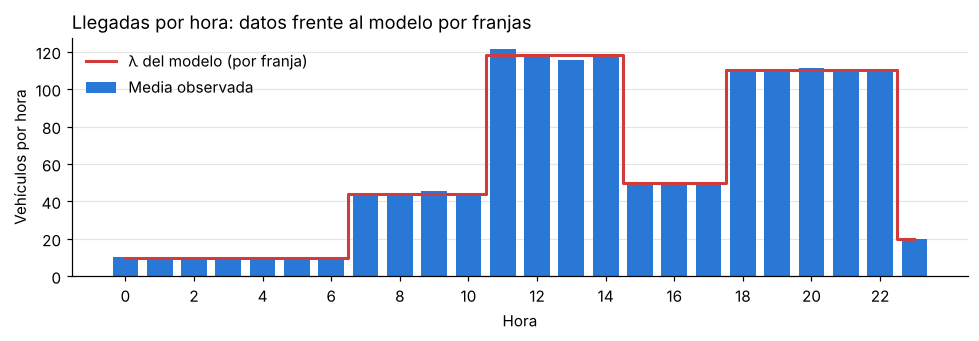

In [4]:
n = ajuste.llegadas_por_hora(df)
por_hora = n.groupby("Hora")["n"].agg(["mean", "var"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(por_hora.index, por_hora["mean"], color=AZUL, width=0.75, label="Media observada")
lam = S.lambdas_por_hora(modelos)
ax.step(np.arange(24), lam, where="mid", color=ROJO, lw=2, label="λ del modelo (por franja)")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hora"); ax.set_ylabel("Vehículos por hora")
ax.set_title("Llegadas por hora: datos frente al modelo por franjas", loc="left")
ax.legend(frameon=False); ax.grid(axis="y", color="#e5e5e5"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Lectura:**
- En todas las franjas la **varianza es casi igual a la media** (índice de dispersión entre 0,84 y 1,13) y la prueba χ² de bondad de ajuste no rechaza la Poisson (p > 0,1). Dentro de cada franja, las horas no difieren entre sí (ANOVA, p > 0,2), así que basta **una tasa por franja**.
- **Excepción, no detectada en la práctica original:** en *Llano (Mañana)* la demanda **crece a lo largo del mes** (pendiente +0,22 veh/h por día, p = 0,003; sigue siendo significativa con la corrección de Bonferroni para 6 franjas). Pasa de 41,8 a 46,0 vehículos/hora entre la primera y la segunda quincena. El modelo usa la media y la app permite simular más demanda; con más datos convendría modelizar la tendencia.

### 3.2 Tipo de cargador

In [5]:
mz = modelos["mezcla"]
t = pd.DataFrame({"AP-7": mz["p"], "España": [C.CUOTA_ESPANA[x] for x in C.NOMBRES]}, index=C.NOMBRES)
display(t.round(3))
print(f"χ² de homogeneidad de la mezcla entre franjas: p = {mz['p_homogeneidad_franjas']:.3f}")

,AP-7,España
AC/PHEV,0.149,0.3
DC Estándar,0.350,0.4
HPC 150,0.403,0.2
HPC 350,0.098,0.1


χ² de homogeneidad de la mezcla entre franjas: p = 0.224


En autopista hay **la mitad de PHEV y el doble de HPC 150** que en el mercado español: los híbridos usan gasolina en viajes largos y los Tesla dominan la ruta. La mezcla **no depende de la franja** (p = 0,22), así que el número de vehículos de cada tipo en una hora con N llegadas es una **Multinomial(N, p)**.

### 3.3 Energía y potencia

Para cada tipo se ajustan seis distribuciones candidatas por máxima verosimilitud (normal, uniforme, lognormal, gamma, Weibull y exponencial) y se elige la de **menor AIC**. El p-valor de Kolmogorov-Smirnov sirve como comprobación. Es optimista, porque los parámetros se estiman con los mismos datos, así que se usa solo para descartar ajustes claramente malos.

In [6]:
filas = []
for var in ["energia", "potencia"]:
    for tipo in C.NOMBRES:
        s = modelos[var][tipo]
        if s["dist"] == "constante":
            filas.append({"variable": var, "tipo": tipo, "elegida": f"constante {s['valor']:g}"})
            continue
        orden = sorted(s["candidatas"].items(), key=lambda kv: kv[1]["aic"])
        filas.append({"variable": var, "tipo": tipo, "elegida": s["dist"],
                      "parámetros": [round(v, 2) for v in s["params"]], "KS p": round(s["ks_p"], 3),
                      "2ª mejor": orden[1][0], "ΔAIC con la 2ª": round(orden[1][1]["aic"] - s["aic"])})
pd.DataFrame(filas)

,variable,tipo,elegida,parámetros,KS p,2ª mejor,ΔAIC con la 2ª
0,energia,AC/PHEV,gamma,"[3.02, 0.0, 3.98]",0.946,weibull_min,222.0
1,energia,DC Estándar,norm,"[25.0, 4.99]",0.778,weibull_min,421.0
2,energia,HPC 150,norm,"[50.02, 10.01]",0.857,weibull_min,452.0
3,energia,HPC 350,uniform,"[50.03, 39.95]",0.914,norm,1512.0
4,potencia,AC/PHEV,constante 11,NaN,NaN,NaN,NaN
5,potencia,DC Estándar,constante 50,NaN,NaN,NaN,NaN
6,potencia,HPC 150,uniform,"[80.0, 50.0]",0.413,norm,6244.0
7,potencia,HPC 350,norm,"[200.49, 19.91]",0.969,gamma,28.0


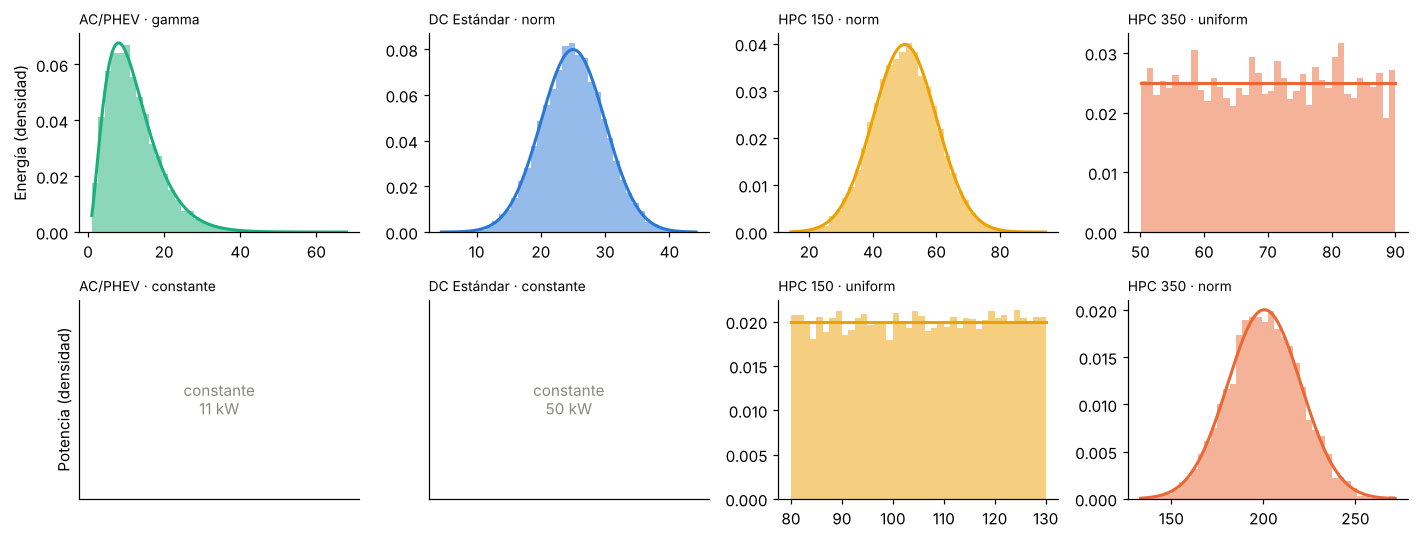

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for fila, var, col in [(0, "energia", "Energía_kWh"), (1, "potencia", "Potencia_kW")]:
    for j, tipo in enumerate(C.NOMBRES):
        ax = axes[fila, j]; x = df.loc[df["Tipo"] == tipo, col]; s = modelos[var][tipo]
        if s["dist"] == "constante":
            ax.text(0.5, 0.5, f"constante\n{s['valor']:g} kW", ha="center", va="center", transform=ax.transAxes, color=GRIS)
            ax.set_xticks([]); ax.set_yticks([])
        else:
            ax.hist(x, bins=40, density=True, color=COL[tipo], alpha=0.5)
            xs = np.linspace(x.min(), x.max(), 300)
            ax.plot(xs, getattr(stats, s["dist"]).pdf(xs, *s["params"]), color=COL[tipo], lw=2)
        ax.set_title(f"{tipo} · {s['dist']}", fontsize=9, loc="left")
axes[0, 0].set_ylabel("Energía (densidad)"); axes[1, 0].set_ylabel("Potencia (densidad)")
plt.tight_layout(); plt.show()

In [8]:
# ¿Dependen la energía y la potencia de la franja? ¿Están correlacionadas?
filas = []
for tipo, g in df.groupby("Tipo"):
    p_e = stats.kruskal(*[x["Energía_kWh"] for _, x in g.groupby("Tipo_Franja")]).pvalue
    p_p = stats.kruskal(*[x["Potencia_kW"] for _, x in g.groupby("Tipo_Franja")]).pvalue if g["Potencia_kW"].nunique() > 1 else np.nan
    rho = stats.spearmanr(g["Energía_kWh"], g["Potencia_kW"]).correlation if g["Potencia_kW"].nunique() > 1 else np.nan
    filas.append({"tipo": tipo, "p Kruskal energía~franja": round(p_e, 3), "p Kruskal potencia~franja": round(p_p, 3), "Spearman E–P": round(rho, 3)})
pd.DataFrame(filas)

,tipo,p Kruskal energía~franja,p Kruskal potencia~franja,Spearman E–P
0,AC/PHEV,0.573,NaN,NaN
1,DC Estándar,0.520,NaN,NaN
2,HPC 150,0.831,0.922,0.013
3,HPC 350,0.898,0.325,-0.006


Los ajustes salen muy claros: la ganadora por AIC supera a la segunda por cientos o miles de puntos en casi todos los casos, y su KS no rechaza. La energía y la potencia **no dependen de la franja** (p > 0,3) y **no están correlacionadas**, así que se simulan de forma independiente según el tipo. Que los ajustes sean tan buenos (normales casi perfectas, uniformes con extremos exactos) indica que los datos son **sintéticos**, y por eso las conclusiones son sobre el método más que sobre una estación real.

## 4. Simulador y validación

Por cada hora: `N ~ Poisson(λ_franja)`, tipos `~ Multinomial(N, p)`, energía y potencia según el tipo; `PIT = Σ P`, `BB = Σ E·(PVP − 0,20)`. Hay corte si `PIT > límite + batería`. **Beneficio neto = BB − BB perdido en cortes − coste de los cortes − alquiler de la batería.**

La implementación está vectorizada con NumPy: cada mes simulado es un puñado de operaciones sobre vectores en lugar de bucles por vehículo.

In [9]:
import time
t0 = time.perf_counter()
sim = S.simular(modelos, S.Escenario(), n_sims=500, seed=2026)
print(f"500 meses simulados en {time.perf_counter() - t0:.2f} s")
met = S.evaluar(sim)
obs = modelos["empirico"]["resumen_mes"]
val = pd.DataFrame({
    "simulado (media)": [met["vehiculos"].mean(), met["energia_kwh"].mean(), met["beneficio_bruto"].mean(), met["pit_p99"].mean(), met["cortes"].mean()],
    "rango simulado (P5 – P95)": [f"{met['vehiculos'].quantile(.05):,.0f} – {met['vehiculos'].quantile(.95):,.0f}",
                         f"{met['energia_kwh'].quantile(.05):,.0f} – {met['energia_kwh'].quantile(.95):,.0f}",
                         f"{met['beneficio_bruto'].quantile(.05):,.0f} – {met['beneficio_bruto'].quantile(.95):,.0f}",
                         f"{met['pit_p99'].quantile(.05):,.0f} – {met['pit_p99'].quantile(.95):,.0f}",
                         f"{met['cortes'].quantile(.05):.0f} – {met['cortes'].quantile(.95):.0f}"],
    "observado (mes real)": [obs["vehiculos"], obs["energia_kwh"], obs["bb_eur"], obs["pit_p99"], obs["horas_sobre_limite"]],
}, index=["Vehículos", "Energía (kWh)", "Beneficio bruto (€)", "P99 de la PIT (kW)", "Horas sobre el límite"])
for col in ["simulado (media)", "observado (mes real)"]:
    val[col] = val[col].map(lambda v: f"{v:,.1f}" if v < 100 else f"{v:,.0f}")
val

500 meses simulados en 1.31 s


,simulado (media),rango simulado (P5 – P95),observado (mes real)
Vehículos,"43,094","42,766 – 43,453","43,076"
Energía (kWh),"1,619,000","1,604,842 – 1,633,596","1,618,734"
Beneficio bruto (€),"593,474","587,563 – 599,683","593,466"
P99 de la PIT (kW),"11,380","11,100 – 11,672","11,406"
Horas sobre el límite,6.1,3 – 10,5.0


**Todos los valores del mes real caen dentro del rango P5–P95 de los meses simulados**, y las medias coinciden con un error inferior al 0,3 %. El simulador también reproduce los resultados de la práctica original: beneficio neto ≈ 567 000 € al mes sin batería, frente a 567 620 € en la práctica.

## 5. ¿Alquilar baterías?

La práctica original dimensionaba la batería con la **regla del P99**: cubrir el déficit del percentil 99 de la PIT en la franja crítica. Aquí se calcula la **curva completa de beneficio neto frente a kW** con **números aleatorios comunes**: todos los tamaños se evalúan sobre los mismos meses y los mismos costes de corte, así que la curva es suave y las diferencias entre tamaños se deben a la batería.

In [10]:
base = dict(zip(C.NOMBRES, modelos["mezcla"]["p"]))
casos = {"Situación actual": S.Escenario(),
         "HPC 350 +10 pp": S.Escenario(cuotas=E.cambiar_cuota(base, "HPC 350", base["HPC 350"] + 0.10)),
         "Demanda +25 %": S.Escenario(factor_demanda=1.25)}
resultados = {}
for nombre, esc in casos.items():
    sim_c = S.simular(modelos, esc, n_sims=300, seed=2026)
    resultados[nombre] = E.regla_p99_vs_optima(sim_c)
pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "curva"} for k, v in resultados.items()}).T.astype(float).round(0)

,regla_kw,regla_redondeada_kw,bn_regla,optima_kw,bn_optima,ganancia_optima_vs_regla
Situación actual,503.0,500.0,534232.0,0.0,566633.0,32401.0
HPC 350 +10 pp,2464.0,2500.0,451733.0,1300.0,509906.0,58172.0
Demanda +25 %,3185.0,3200.0,413026.0,2100.0,466980.0,53954.0


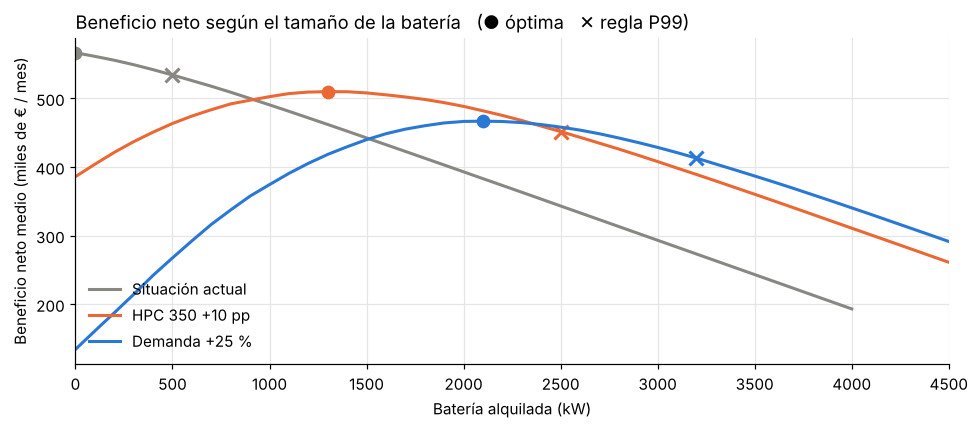

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for (nombre, r), color in zip(resultados.items(), [GRIS, NARANJA, AZUL]):
    c = r["curva"]
    ax.plot(c["bateria_kw"], c["bn_media"] / 1000, color=color, lw=2, label=nombre)
    ax.plot(r["optima_kw"], r["bn_optima"] / 1000, "o", color=color, ms=8)
    ax.plot(r["regla_redondeada_kw"], r["bn_regla"] / 1000, "x", color=color, ms=9, mew=2)
ax.set_xlabel("Batería alquilada (kW)"); ax.set_ylabel("Beneficio neto medio (miles de € / mes)")
ax.set_title("Beneficio neto según el tamaño de la batería   (● óptima   ✕ regla P99)", loc="left")
ax.set_xlim(0, 4500); ax.grid(color="#e5e5e5"); ax.set_axisbelow(True); ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

**Lectura:**
- **Situación actual:** el óptimo es **no alquilar**. Cada 100 kW cuestan 10 000 € al mes y evitan ~1 corte, que cuesta unos 4 000 € entre reparación e ingresos perdidos.
- **HPC 350 +10 pp y demanda +25 %:** la batería es imprescindible, pero el **óptimo está muy por debajo de la regla del P99**, y con él se ganan **decenas de miles de euros al mes más**. La regla cubre el 99 % de los picos, cuando los últimos kW evitan cortes tan raros que valen menos que su alquiler.
- Cerca del óptimo la curva es **plana**: ±200 kW apenas cambian el resultado. Es un margen útil para negociar el contrato de alquiler.

## 6. Escenarios

In [12]:
comp = E.comparar(modelos, S.Escenario(), n_sims=200, seed=2026)
comp.drop(columns="descripcion").set_index("escenario").round(0)

,bb_media,bn_sin_bateria,cortes_sin_bateria,pit_p99,bateria_optima_kw,bn_con_optima,mejora_bateria,bateria_regla_p99_kw,cortes_con_optima,bn_vs_actual
escenario,,,,,,,,,,
Situación actual,593398.0,566715.0,6.0,11381.0,0.0,566715.0,0.0,500.0,6.0,0.0
Demanda +25 %,742084.0,135503.0,136.0,13942.0,2100.0,466221.0,330718.0,3189.0,14.0,-100494.0
Fin de subsidios PHEV,640556.0,533747.0,24.0,12183.0,400.0,542333.0,8586.0,1329.0,13.0,-24381.0
HPC 350 +10 pp,711604.0,385939.0,72.0,13241.0,1400.0,509414.0,123475.0,2455.0,13.0,-57301.0
Energía +10 %,561019.0,534997.0,6.0,11381.0,0.0,534997.0,0.0,500.0,6.0,-31717.0
Electrificación rápida,889264.0,-274550.0,246.0,16275.0,4200.0,383599.0,658149.0,5608.0,16.0,-183116.0


**Lecturas:**
- **Más clientes no es más dinero si la red no acompaña.** Con la demanda +25 % el beneficio bruto sube un 25 %, pero sin batería el neto se hunde por más de cien cortes al mes.
- **Fin de los subsidios PHEV:** el beneficio **bruto sube**, porque se sustituyen recargas lentas y baratas por otras rápidas y caras, pero el **neto baja** por los picos de potencia. En la práctica original se miraba solo el beneficio bruto y la respuesta escrita decía que bajaba, aunque las cifras mostraban que subía (de 138 666 € a 150 023 € a la semana). Con el beneficio neto la conclusión cambia: el neto sí baja.
- **El coste de la energía no cambia los cortes**, solo el margen.
- **Electrificación rápida** (demanda +25 % y HPC 350 +10 pp): sin batería, el beneficio neto es **negativo**.

## 7. Decisiones técnicas

| Decisión | Motivo |
|---|---|
| Ajuste propio con `scipy` (6 candidatas, AIC) | Sustituye las funciones de la asignatura (no redistribuibles) y hace explícito el criterio de selección |
| AIC para elegir y KS solo como comprobación | El KS con parámetros estimados con los mismos datos es optimista; el AIC compara modelos de distinta complejidad |
| Simulación vectorizada (Poisson → Multinomial → `np.repeat` + `np.bincount`) | ~1 000 veces más rápida que un bucle por vehículo; permite una app interactiva |
| Números aleatorios comunes para comparar decisiones | Las diferencias entre tamaños de batería o escenarios se deben a la decisión, no al ruido Monte Carlo |
| Coste de corte simulado por hora una sola vez | Mantiene la coherencia entre tamaños de batería |
| Curva completa en vez de regla del P99 | La decisión económica óptima depende del coste del kW, no solo de la distribución de los picos |
| Solo parámetros y agregados en el repositorio | Los datos son de un repositorio docente sin licencia explícita; se citan y se descargan de la fuente |

## 8. Limitaciones

- **PIT horaria = suma de potencias de las llegadas de esa hora** (supuesto del caso). No modela el solapamiento real de recargas (duración `E / (0,9·P)`), ni su reparto dentro de la hora, ni la reducción de potencia por encima del 80 % de batería. Es la mejora natural siguiente: una simulación de eventos discretos.
- La batería se supone limitada solo por potencia (energía suficiente para el pico).
- Tasas de llegada constantes en el tiempo: en los datos, *Llano (Mañana)* crece.
- Los datos son sintéticos: el método es trasladable, pero las cifras no describen una estación real.

## 9. Registro de cambios

| Fecha | Cambio |
|---|---|
| 16/10/2026 | Exploración de los datos y ajuste propio de llegadas, mezcla, energía y potencia con validación estadística |
| 16/10/2026 | Simulador Monte Carlo vectorizado, validado frente al mes real y a la práctica original |
| 16/10/2026 | Curva de beneficio frente a batería con números aleatorios comunes; comparación con la regla del P99 |
| 16/10/2026 | Seis escenarios estratégicos; app Streamlit de cinco páginas; 25 tests y CI |